# Cirq · 量子游走与波动情景

Quantum walk & volatility scenarios

[金融 Cirq 总目录](cirq_finance.html) · **QuantumBridge 原创金融教学扩展 / Cirq 本地仿真**

五步量子游走与经典二项分布对照，观察干涉改变情景权重。

合成模型；不是投资建议，不是完整行业支持，也不证明 QuantumBridge 原生替代 Cirq。

## 1. 官方方法与归属 / Sources

Google 官方确有 Quantum walk 教程，并提及随机游走与金融的联系；官方例子没有完成金融定价或波动率模型。此处为我们独立编写的小规模情景扩展，不是行情预测、相关性估计或训练完成的金融 AI。

- [Google Cirq · Quantum walk](https://quantumai.google/cirq/experiments/quantum_walks)
- [Google Cirq · Simulation](https://quantumai.google/cirq/simulate/simulation)

## 2. 原理与步骤 / Model & workflow

4 个位置量子比特编码 16 个点，另加 1 个硬币位。初始位置为 8，
硬币态 $(|0\rangle+i|1\rangle)/\sqrt{2}$。每步先施加 H，再按硬币值向左或向右移动。
步算符 $U=S(H\otimes I)$；移位使用循环置换，但 5 步只到位置 3 至 13，未跨边界。
经典对照为相同起点和步数、独立公平抛币的二项分布。
可将位移乘 1% 作为**示意情景**，但量子干涉概率不是已经校准的市场价格过程。

设定起点与平衡硬币 → 五次硬币 / 受控移位 → 每步位置边缘概率 → 独立振幅递推校验 → 4096 次最终采样 → 对照经典游走。

## 3. 运行环境 / Local environment

需要已安装 `cirq`、`numpy`、`matplotlib` 与 Jupyter。代码不依赖本仓库私有模块，可在安装上述依赖的 Python 内核从上到下运行。没有自动安装、联网或密钥读取。

In [1]:
import json, sys
import cirq
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML

SEED, SHOTS = 20261101, 4096
simulator = cirq.Simulator(dtype=np.complex128, seed=SEED)
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
print('Backend: local cirq.Simulator | Cirq:', cirq.__version__)
print('Python:', sys.version.split()[0], '| hardware jobs: 0')
print('Bit order: q0 first / most significant bit; synthetic data only.')

def probabilities(circuit, qubits):
    state = simulator.simulate(circuit, qubit_order=qubits).final_state_vector
    return np.abs(state)**2

def measured_counts(circuit, qubits, key='out'):
    measured = circuit + cirq.Circuit(cirq.measure(*qubits, key=key))
    histogram = simulator.run(measured, repetitions=SHOTS).histogram(key=key)
    return np.array([histogram.get(i, 0) for i in range(2**len(qubits))], dtype=int)

def compare_plot(labels, exact, sampled, title):
    x = np.arange(len(labels))
    fig, ax = plt.subplots(figsize=(8, 3.3), layout='constrained')
    ax.bar(x-.18, exact, .36, label='Exact model', color='#137f76')
    ax.bar(x+.18, sampled, .36, label='4096 local Cirq shots', color='#bc4164')
    ax.set(xticks=x, xticklabels=labels, ylabel='Probability', title=title)
    ax.legend()
    plt.show()

Backend: local cirq.Simulator | Cirq: 1.6.1
Python: 3.12.6 | hardware jobs: 0
Bit order: q0 first / most significant bit; synthetic data only.


## 4. 输入与电路 / Inputs & circuit

In [2]:
from math import comb
coin, *position = cirq.LineQubit.range(5)
order = [coin, *position]
size, start, steps = 16, 8, 5

## 5. 中间结果与实际本地采样 / Intermediate & sampled results

图中 Exact 为同一模型的精确分布；Cirq shots 为有限次模拟测量，不是真机回执。

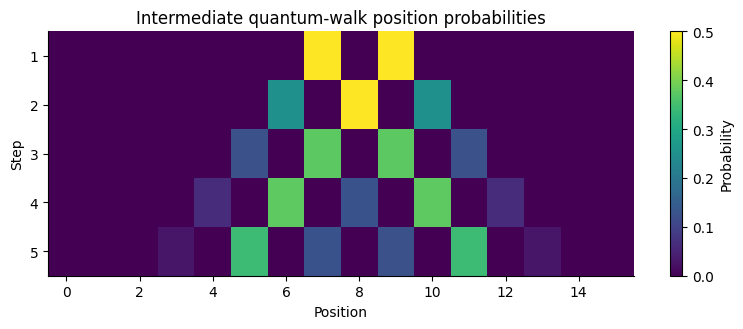

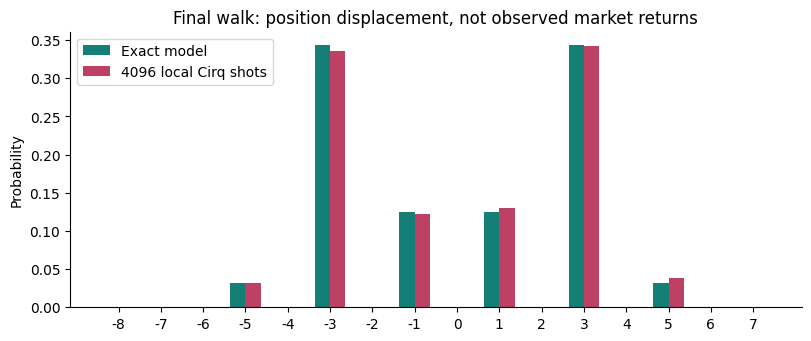

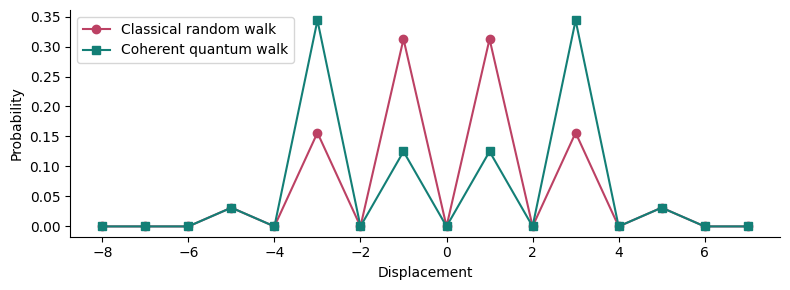

In [3]:
# A transparent finite permutation, not a market-fitted transition model.
plus = np.roll(np.eye(size), 1, axis=0)
minus = plus.T
circuit = cirq.Circuit(cirq.X(position[0]), cirq.H(coin), cirq.S(coin))
recurrence = np.zeros((2, size), dtype=complex)
recurrence[:,start] = [1/np.sqrt(2), 1j/np.sqrt(2)]
snapshots = []
for _ in range(steps):
    circuit.append(cirq.H(coin))
    circuit.append(cirq.MatrixGate(plus).on(*position)
                   .controlled_by(coin, control_values=[1]))
    circuit.append(cirq.MatrixGate(minus).on(*position)
                   .controlled_by(coin, control_values=[0]))
    state = simulator.simulate(circuit, qubit_order=order).final_state_vector.reshape(2,size)
    marginal = np.abs(state[0])**2 + np.abs(state[1])**2
    mixed = np.array([recurrence[0]+recurrence[1], recurrence[0]-recurrence[1]])/np.sqrt(2)
    recurrence = np.array([np.roll(mixed[0], -1), np.roll(mixed[1], 1)])
    assert np.allclose(state, recurrence, atol=1e-12)
    snapshots.append(marginal.tolist())
exact = np.array(snapshots[-1])
classical = np.zeros(size)
for right in range(steps+1):
    classical[start+2*right-steps] = comb(steps,right)/2**steps
counts = measured_counts(circuit, position)
assert np.isclose(exact.sum(), 1) and np.isclose(classical.sum(), 1)
assert not np.allclose(exact, classical)
assert np.isclose(exact @ (np.arange(size)-start), 0, atol=1e-12)
plt.figure(figsize=(8,3.4))
plt.imshow(snapshots, aspect='auto', cmap='viridis', interpolation='nearest')
plt.yticks(range(steps), range(1,steps+1)); plt.xlabel('Position'); plt.ylabel('Step')
plt.title('Intermediate quantum-walk position probabilities'); plt.colorbar(label='Probability')
plt.tight_layout(); plt.show()
compare_plot([str(i-start) for i in range(size)], exact, counts/SHOTS,
             'Final walk: position displacement, not observed market returns')
plt.figure(figsize=(8,3))
plt.plot(np.arange(size)-start, classical, 'o-', label='Classical random walk', color='#bc4164')
plt.plot(np.arange(size)-start, exact, 's-', label='Coherent quantum walk', color='#137f76')
plt.xlabel('Displacement'); plt.ylabel('Probability'); plt.legend(); plt.tight_layout(); plt.show()
displacement = np.arange(size)-start
evidence = {'qubits': 5, 'shots': SHOTS, 'counts': counts.tolist(), 'steps': steps,
            'ideal_probability': exact.tolist(), 'classical_probability': classical.tolist(),
            'intermediate_probability': snapshots,
            'quantum_variance': float(exact @ displacement**2),
            'classical_variance': float(classical @ displacement**2),
            'validation': 'All five Cirq step states checked against independent amplitude recurrence'}

## 6. 最终输出与边界 / Evidence & limitations

Google 官方确有 Quantum walk 教程，并提及随机游走与金融的联系；官方例子没有完成金融定价或波动率模型。此处为我们独立编写的小规模情景扩展，不是行情预测、相关性估计或训练完成的金融 AI。

本次硬件任务为 0。不同 SDK 版本的随机抽样序列可能不同，解析断言仍应成立。

In [4]:
evidence.update({'backend': 'local cirq.Simulator', 'cirq_version': cirq.__version__, 'python': sys.version.split()[0], 'seed': SEED, 'hardware_jobs': 0})
print('EVIDENCE_JSON=' + json.dumps(evidence, ensure_ascii=False, allow_nan=False))

EVIDENCE_JSON={"qubits": 5, "shots": 4096, "counts": [0, 0, 0, 129, 0, 1377, 0, 501, 0, 532, 0, 1401, 0, 156, 0, 0], "steps": 5, "ideal_probability": [0.0, 0.0, 0.0, 0.03125000000000001, 0.0, 0.34375000000000006, 0.0, 0.12500000000000006, 0.0, 0.125, 0.0, 0.34375000000000006, 0.0, 0.03125000000000001, 0.0, 0.0], "classical_probability": [0.0, 0.0, 0.0, 0.03125, 0.0, 0.15625, 0.0, 0.3125, 0.0, 0.3125, 0.0, 0.15625, 0.0, 0.03125, 0.0, 0.0], "intermediate_probability": [[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.5000000000000001, 0.0, 0.5000000000000001, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.2500000000000001, 0.0, 0.5000000000000002, 0.0, 0.2500000000000001, 0.0, 0.0, 0.0, 0.0, 0.0], [0.0, 0.0, 0.0, 0.0, 0.0, 0.12500000000000003, 0.0, 0.375, 0.0, 0.375, 0.0, 0.12500000000000003, 0.0, 0.0, 0.0, 0.0], [0.0, 0.0, 0.0, 0.0, 0.06250000000000003, 0.0, 0.3750000000000002, 0.0, 0.12500000000000006, 0.0, 0.3750000000000002, 0.0, 0.06250000000000003, 0.0, 0.0, 0.0], [0.0, 0.0, 